<a href="https://colab.research.google.com/github/Prativa239-pd/Prativa239-pd1/blob/main/earth_engine_chhattisgard_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install earthengine-api geemap segmentation-models-pytorch rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.7 MB/s eta 0:00:00


In [ ]:
import ee

ee.Authenticate()

ee.Initialize(project='star-project-503806')

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [ ]:
!pip install earthengine-api geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 73.6 MB/s eta 0:00:00


In [ ]:
# Actual Chhattisgarh administrative boundary
import ee
import geemap

chhattisgarh = (
    ee.FeatureCollection("FAO/GAUL/2015/level1")
    .filter(ee.Filter.eq("ADM0_NAME", "India"))
    .filter(ee.Filter.eq("ADM1_NAME", "Chhattisgarh"))
)

chhattisgarh_region = chhattisgarh.geometry()

print("Actual Chhattisgarh boundary loaded")

✅ Actual Chhattisgarh boundary loaded


/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


In [ ]:
start_date = '2020-06-01'
end_date = '2020-10-31'

b_start, b_end = '2020-06-01', '2020-07-15'
m_start, m_end = '2020-07-16', '2020-09-15'
e_start, e_end = '2020-09-16', '2020-10-31'

def create_composite(region, start_date, end_date, bands):

    s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR')
                     .filterBounds(region)
                     .filterDate(start_date, end_date)
                     .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                     .select(bands))


    s1_collection = (ee.ImageCollection('COPERNICUS/S1_GRD')
                     .filterBounds(region)
                     .filterDate(start_date, end_date)
                     .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
                     .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
                     .filter(ee.Filter.eq('instrumentMode', 'IW'))
                     .select(['VH', 'VV']))

    s2_median = s2_collection.median().clip(region)
    s1_median = s1_collection.median().clip(region)

    return s2_median, s1_median

s2_bands = ['B4', 'B8', 'B11']
s1_bands = ['VH', 'VV']

s2_b, _ = create_composite(chhattisgarh_region, b_start, b_end, s2_bands)
s2_m, _ = create_composite(chhattisgarh_region, m_start, m_end, s2_bands)
s2_e, _ = create_composite(chhattisgarh_region, e_start, e_end, s2_bands)

_, s1_b = create_composite(chhattisgarh_region, b_start, b_end, s1_bands)
_, s1_m = create_composite(chhattisgarh_region, m_start, m_end, s1_bands)
_, s1_e = create_composite(chhattisgarh_region, e_start, e_end, s1_bands)

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/S2_SR! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/S2_SR_HARMONIZED

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR

  warnings.warn(warning, category=DeprecationWarning)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import numpy as np
from sklearn.model_selection import train_test_split
from tqdm import tqdm

import segmentation_models_pytorch as smp

class RiceDataset(Dataset):
    def __init__(self, images, masks, transform=None):
        self.images = images
        self.masks = masks
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]
        mask = self.masks[idx]

        image = torch.tensor(image, dtype=torch.float32).permute(2, 0, 1)
        mask = torch.tensor(mask, dtype=torch.long).squeeze()

        return image, mask


def create_dummy_data(num_samples=100, img_size=128, num_channels=3):
    images = []
    masks = []
    for _ in range(num_samples):

        image = np.random.randint(0, 255, (img_size, img_size, num_channels), dtype=np.uint8)

        mask = np.random.randint(0, 2, (img_size, img_size, 1), dtype=np.uint8)
        images.append(image)
        masks.append(mask)
    return images, masks


X, y = create_dummy_data(num_samples=200)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

train_dataset = RiceDataset(X_train, y_train)
val_dataset = RiceDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

# %% [markdown]
# **Initialize the UNET Model**
# The paper uses a UNET architecture. We'll use the one from `smp` which is pre-configured for segmentation.

# %%
# Initialize the UNET model
# in_channels = number of input channels (3 for our composite)
# out_channels = number of output classes (1 for binary segmentation, but CrossEntropyLoss expects 2)
model = smp.Unet(
    encoder_name='resnet34',  # Choose a backbone (encoder)
    encoder_weights='imagenet',  # Use pre-trained ImageNet weights
    in_channels=3,
    classes=2,  # Number of output classes (background and rice)
    activation=None  # We'll use Softmax later
)

# Define the loss function (Cross Entropy for multi-class)
loss_fn = nn.CrossEntropyLoss()

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=3e-4)

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

# Define the metric (IoU)
def compute_iou(pred_mask, true_mask, num_classes=2):
    # pred_mask: (B, H, W) with class indices
    # true_mask: (B, H, W) with class indices
    iou_list = []
    for cls in range(num_classes):
        pred_cls = (pred_mask == cls)
        true_cls = (true_mask == cls)
        intersection = (pred_cls & true_cls).sum().float()
        union = (pred_cls | true_cls).sum().float()
        if union == 0:
            iou = torch.tensor(1.0)  # Perfect score if both are empty
        else:
            iou = (intersection / union)
        iou_list.append(iou)
    return torch.mean(torch.tensor(iou_list))

# Training loop
num_epochs = 30
train_losses = []
val_losses = []
train_ious = []
val_ious = []

print(f"Training on {device}")

for epoch in range(num_epochs):
    # Training phase
    model.train()
    epoch_train_loss = 0.0
    epoch_train_iou = 0.0
    for images, masks in tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs} - Training'):
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        # Calculate loss
        loss = loss_fn(outputs, masks)

        # Backpropagation
        loss.backward()
        optimizer.step()

        epoch_train_loss += loss.item()

        # Calculate IoU for this batch
        preds = torch.argmax(outputs, dim=1)
        batch_iou = compute_iou(preds, masks)
        epoch_train_iou += batch_iou.item()

    avg_train_loss = epoch_train_loss / len(train_loader)
    avg_train_iou = epoch_train_iou / len(train_loader)
    train_losses.append(avg_train_loss)
    train_ious.append(avg_train_iou)

    # Validation phase
    model.eval()
    epoch_val_loss = 0.0
    epoch_val_iou = 0.0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f'Epoch {epoch+1}/{num_epochs} - Validation'):
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, masks)

            epoch_val_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            batch_iou = compute_iou(preds, masks)
            epoch_val_iou += batch_iou.item()

    avg_val_loss = epoch_val_loss / len(val_loader)
    avg_val_iou = epoch_val_iou / len(val_loader)
    val_losses.append(avg_val_loss)
    val_ious.append(avg_val_iou)

    print(f"Epoch {epoch+1}: Train Loss: {avg_train_loss:.4f}, Train IoU: {avg_train_iou:.4f}, Val Loss: {avg_val_loss:.4f}, Val IoU: {avg_val_iou:.4f}")

# %%
# ============================================================================
# Step 6: Save the Trained Model
# ============================================================================

# Save the model state dictionary
torch.save(model.state_dict(), 'unet_rice_mapping_chhattisgarh.pth')
print("Model saved to 'unet_rice_mapping_chhattisgarh.pth'")

# %%
# ============================================================================
# Step 7: Inference on New Data (e.g., a new composite image)
# ============================================================================

# Load the trained model
model = smp.Unet(
    encoder_name='resnet34',
    in_channels=3,
    classes=2,
    activation=None
)
model.load_state_dict(torch.load('unet_rice_mapping_chhattisgarh.pth', map_location=device))
model = model.to(device)
model.eval()

# Create a dummy new sample for inference
new_image = np.random.randint(0, 255, (128, 128, 3), dtype=np.uint8)
input_tensor = torch.tensor(new_image, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)

# Perform inference
with torch.no_grad():
    output = model(input_tensor)
    prediction = torch.argmax(output, dim=1).squeeze().cpu().numpy()

print("Inference complete. Prediction shape:", prediction.shape)

# Visualize the result (optional)
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(new_image)
plt.title('Input Image')
plt.subplot(1, 2, 2)
plt.imshow(prediction, cmap='viridis')
plt.title('Predicted Rice Map')
plt.show()

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Training on cuda


Epoch 1/30 - Validation: 100%|██████████| 5/5 [00:00<00:00, 67.90it/s]


...

Epoch 24/30 - Validation: 100%|██████████| 5/5 [00:00<00:00, 68.32it/s]


Epoch 24: Train Loss: 0.6923, Train IoU: 0.3485, Val Loss: 0.6939, Val IoU: 0.3333


Epoch 25/30 - Validation: 100%|██████████| 5/5 [00:00<00:00, 70.09it/s]


Epoch 25: Train Loss: 0.6921, Train IoU: 0.3499, Val Loss: 0.6940, Val IoU: 0.3334


Epoch 26/30 - Training:  15%|█▌        | 3/20 [00:00<00:00, 20.98it/s]

✅ All libraries imported successfully!
🔨 Creating synthetic training data...
Generating synthetic data...
✅ Created 500 synthetic samples
   Image shape: (128, 128, 3)
   Mask shape: (128, 128)
   Rice pixels in first sample: 2518


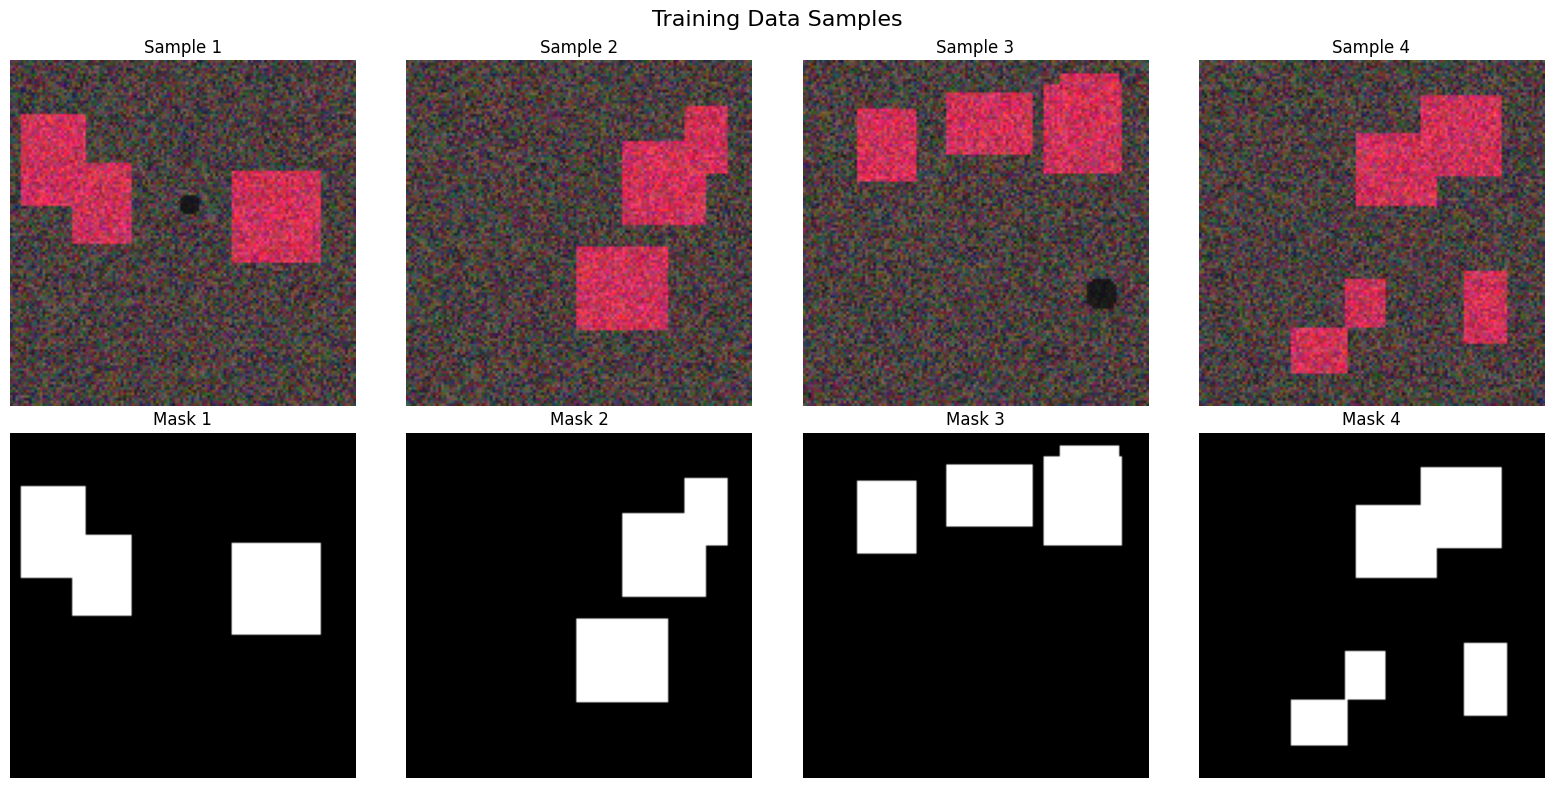

📊 Splitting data...
✅ Training samples: 400
✅ Validation samples: 100
✅ Data loaders created!
🏗️ Building UNET model...
✅ Using device: cuda
✅ Model created!
   Model parameters: 24,436,514
🚀 Starting training...


Epoch 1/30 [Val]: 100%|██████████| 7/7 [00:00<00:00, 44.62it/s]


✅ New best model saved! IoU: 0.5268
Epoch 1: Train Loss=0.3274, Train IoU=0.7976, Val Loss=0.4510, Val IoU=0.5268
------------------------------------------------------------


Epoch 2/30 [Val]: 100%|██████████| 7/7 [00:00<00:00, 49.30it/s]


✅ New best model saved! IoU: 0.9582
Epoch 2: Train Loss=0.1255, Train IoU=0.9731, Val Loss=0.1185, Val IoU=0.9582
------------------------------------------------------------


...

✅ New best model saved! IoU: 0.9992
Epoch 28: Train Loss=0.0023, Train IoU=0.9997, Val Loss=0.0025, Val IoU=0.9992
------------------------------------------------------------


Epoch 29/30 [Val]: 100%|██████████| 7/7 [00:00<00:00, 48.06it/s]


Epoch 29: Train Loss=0.0021, Train IoU=0.9997, Val Loss=0.0023, Val IoU=0.9992
------------------------------------------------------------


Epoch 30/30 [Val]: 100%|██████████| 7/7 [00:00<00:00, 47.67it/s]


✅ New best model saved! IoU: 0.9993
Epoch 30: Train Loss=0.0020, Train IoU=0.9997, Val Loss=0.0022, Val IoU=0.9993
------------------------------------------------------------
✅ Training complete!
📊 Visualizing training results...


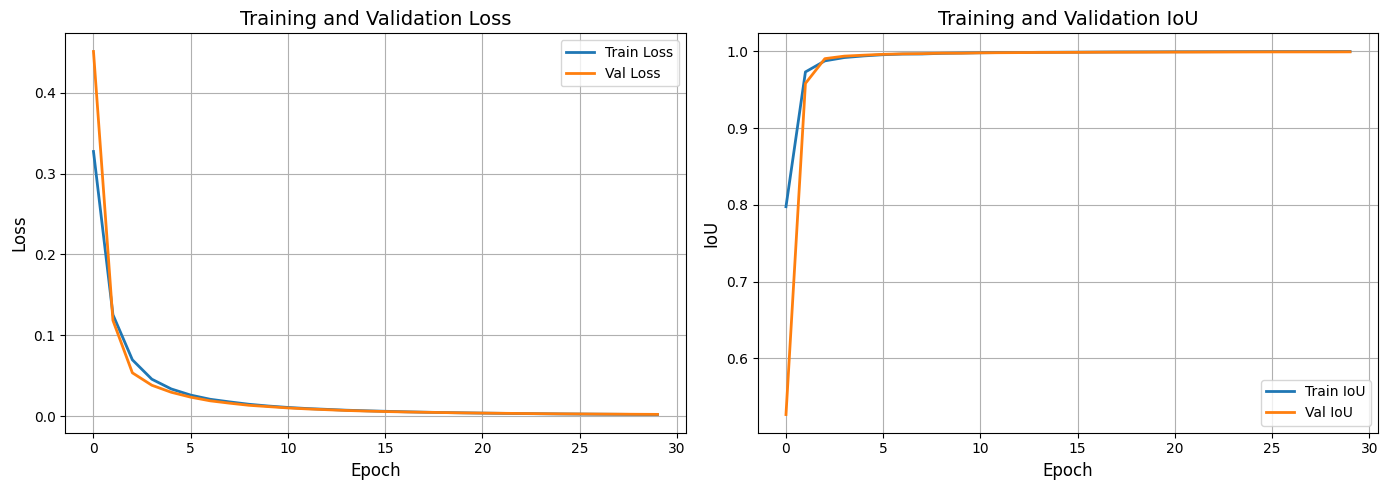

🧪 Testing model on new data...


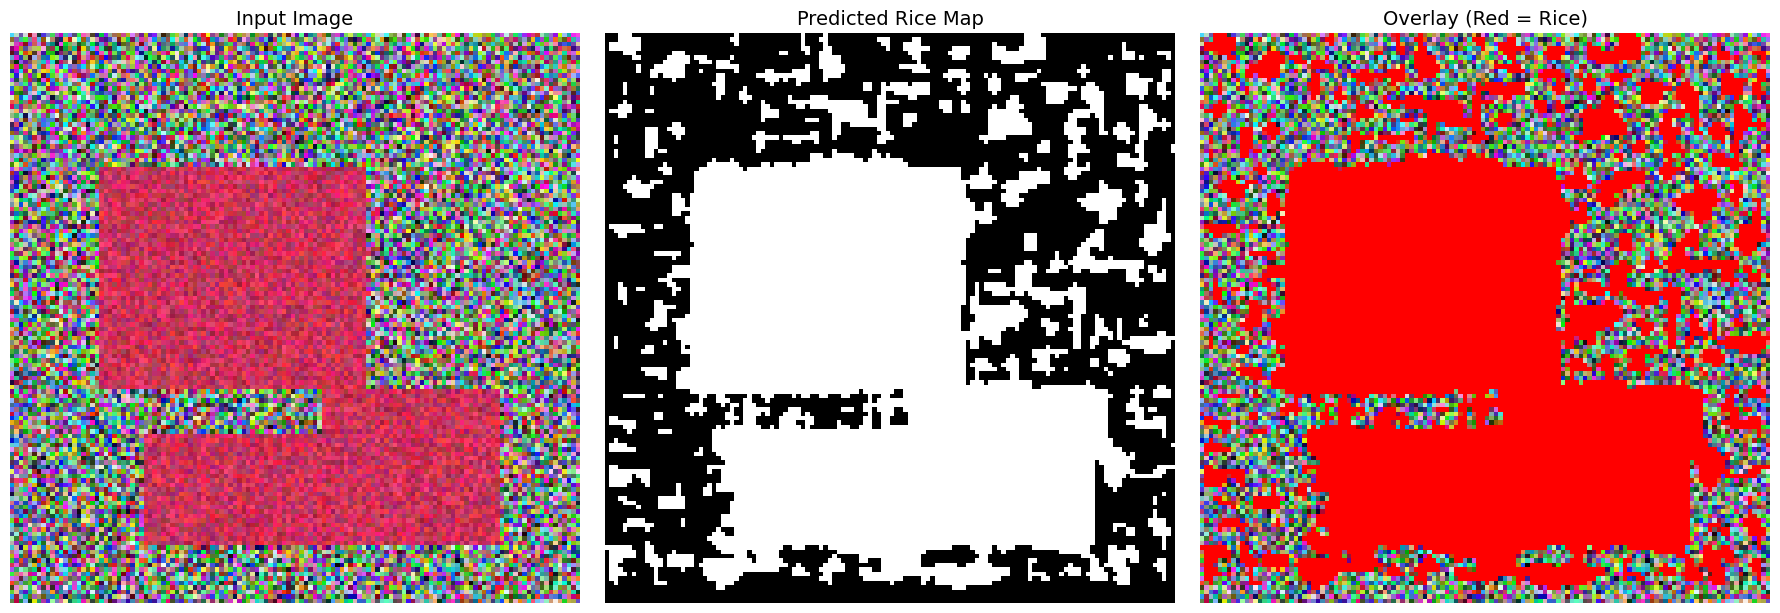

🖼️ Visualizing multiple predictions...


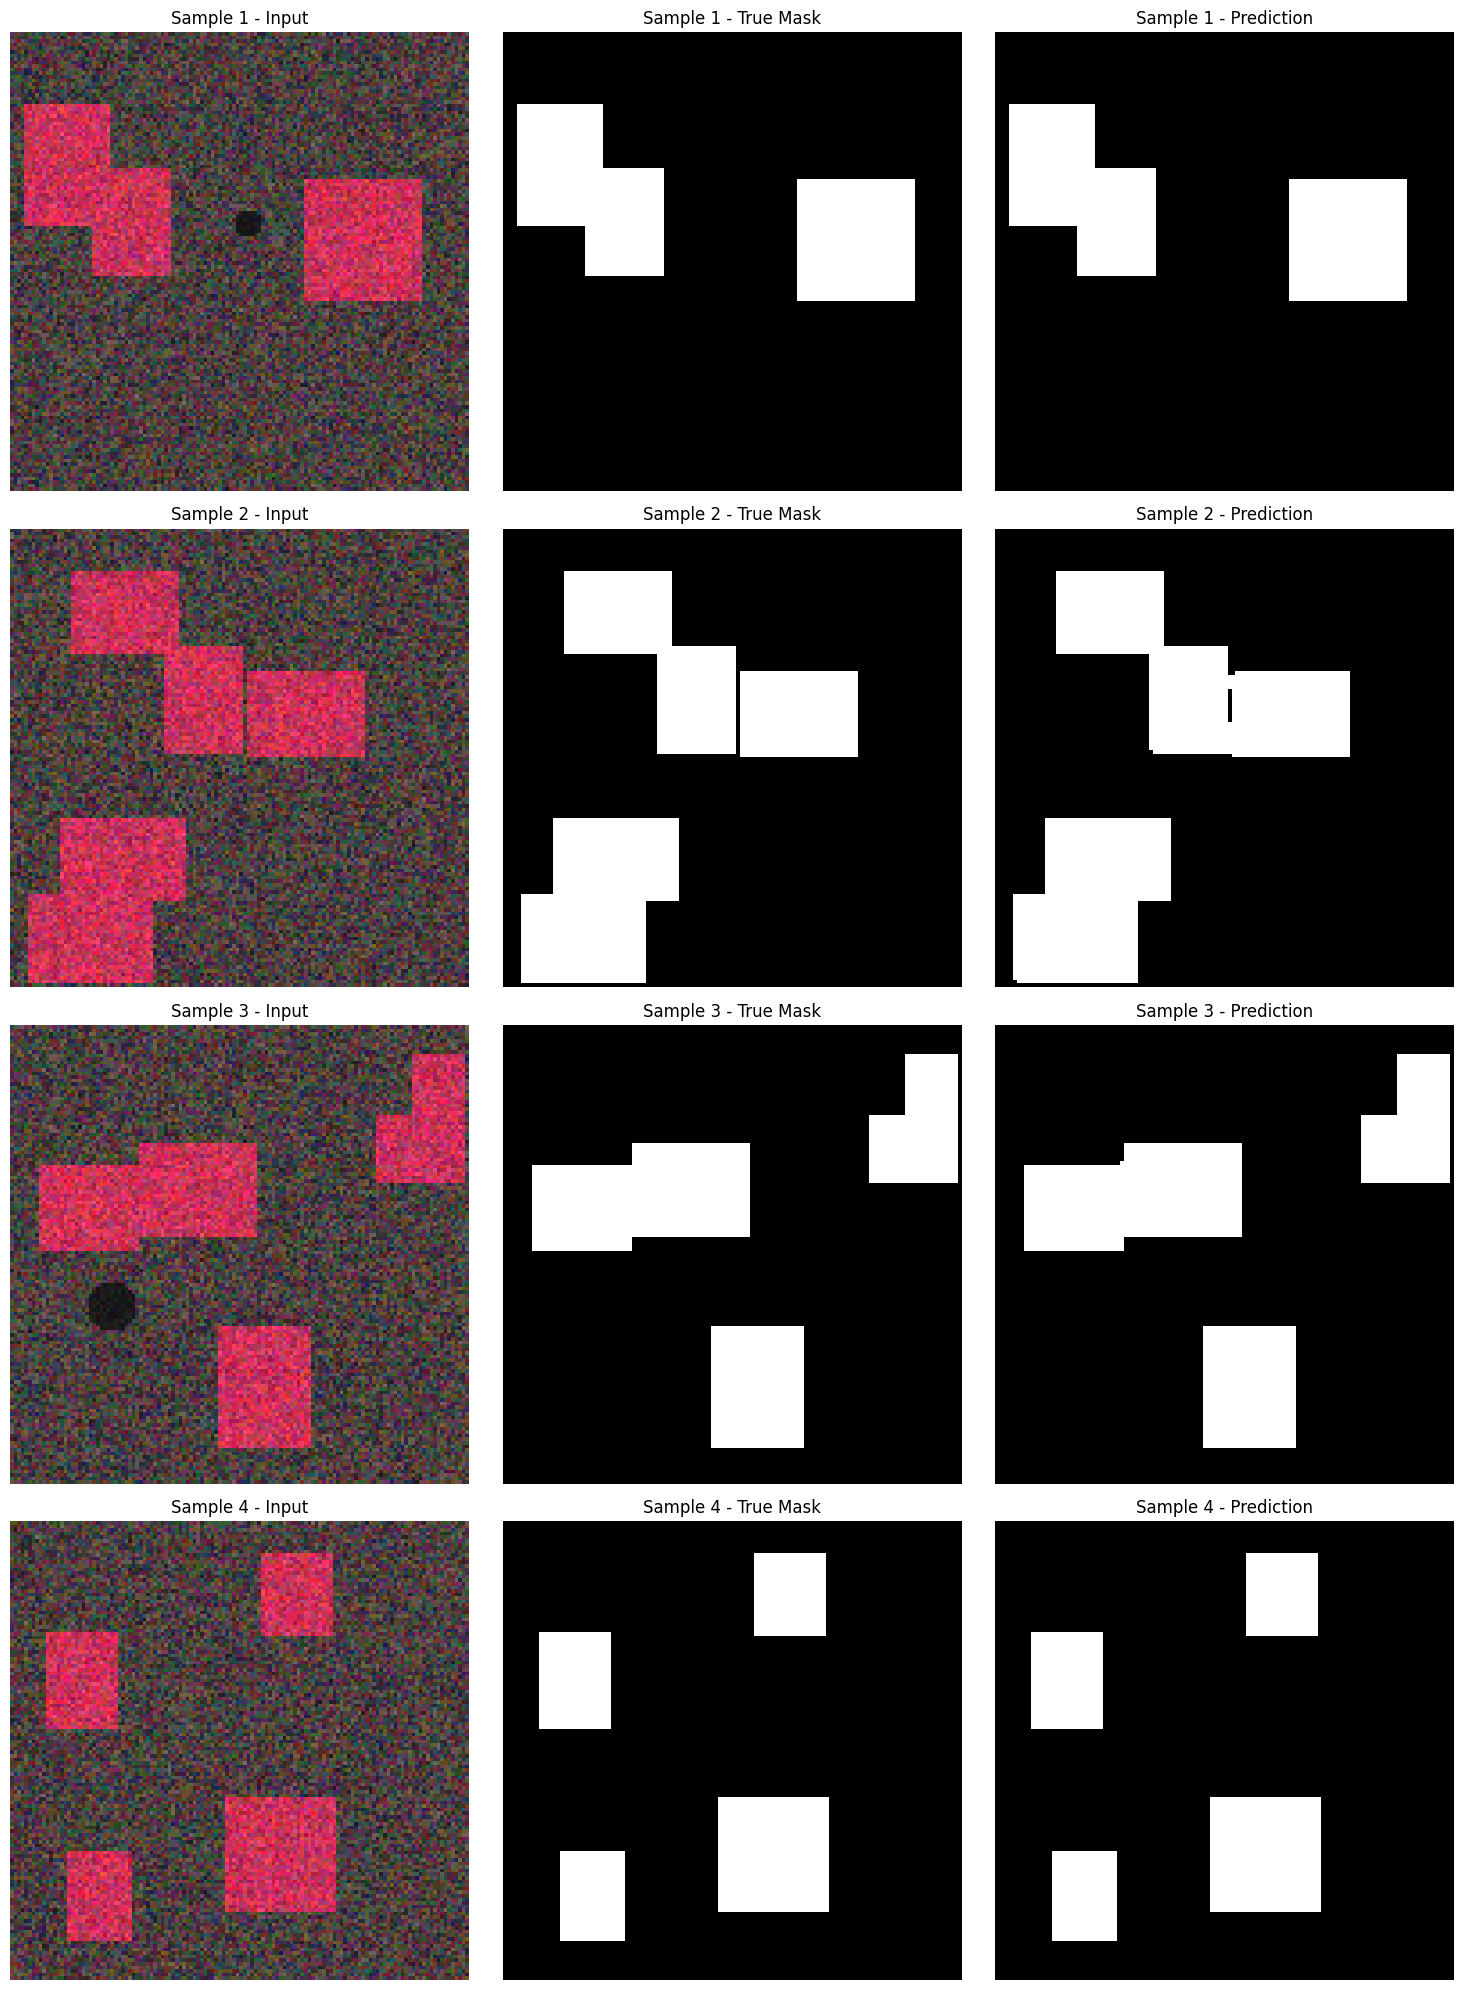

💾 Saving final model...
✅ Model saved as 'unet_rice_model_final.pth'

✅ PROJECT COMPLETED SUCCESSFULLY!
📊 Final Validation IoU: 0.9993
💾 Best model saved as: best_unet_model.pth
💾 Final model saved as: unet_rice_model_final.pth

📝 What you can do next:
1. Train on more samples (increase num_samples to 1000+)
2. Add data augmentation for better generalization
3. Try different model backbones (resnet50, efficientnet)
4. Use real satellite data when Earth Engine is available
5. Deploy the model for rice field mapping


In [ ]:
!pip install segmentation-models-pytorch matplotlib numpy torch tqdm -q

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import segmentation_models_pytorch as smp
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import random

print("✅ All libraries imported successfully!")

print("🔨 Creating synthetic training data...")

def create_realistic_rice_data(num_samples=500, patch_size=128):
    """Create synthetic data that mimics real rice field patterns"""

    images = []
    masks = []

    for _ in range(num_samples):

        image = np.random.rand(patch_size, patch_size, 3).astype(np.float32)

        mask = np.zeros((patch_size, patch_size), dtype=np.float32)

        num_fields = random.randint(2, 5)

        for _ in range(num_fields):
            w = random.randint(15, 35)
            h = random.randint(15, 35)
            x = random.randint(0, patch_size - w - 1)
            y = random.randint(0, patch_size - h - 1)

            mask[y:y+h, x:x+w] = 1.0

            for i in range(y, y+h):
                for j in range(x, x+w):
                    image[i, j, 0] = random.uniform(0.6, 1.0)
                    image[i, j, 1] = random.uniform(0.1, 0.3)
                    image[i, j, 2] = random.uniform(0.2, 0.5)

        for i in range(patch_size):
            for j in range(patch_size):
                if mask[i, j] == 0:
                    image[i, j, 0] = random.uniform(0.1, 0.5)
                    image[i, j, 1] = random.uniform(0.1, 0.4)
                    image[i, j, 2] = random.uniform(0.1, 0.4)

        image += np.random.randn(patch_size, patch_size, 3) * 0.02
        image = np.clip(image, 0, 1)

        if random.random() > 0.6:
            num_features = random.randint(1, 3)
            for _ in range(num_features):
                cx = random.randint(10, patch_size - 10)
                cy = random.randint(10, patch_size - 10)
                r = random.randint(3, 8)
                for i in range(max(0, cy-r), min(patch_size, cy+r)):
                    for j in range(max(0, cx-r), min(patch_size, cx+r)):
                        if (i-cy)**2 + (j-cx)**2 < r**2:
                            mask[i, j] = 0.0
                            image[i, j, 0] = random.uniform(0.05, 0.15)
                            image[i, j, 1] = random.uniform(0.05, 0.15)
                            image[i, j, 2] = random.uniform(0.05, 0.15)

        images.append(image)
        masks.append(mask)

    return np.array(images), np.array(masks)

print("Generating synthetic data...")
X, y = create_realistic_rice_data(num_samples=500, patch_size=128)

print(f"✅ Created {len(X)} synthetic samples")
print(f"   Image shape: {X[0].shape}")
print(f"   Mask shape: {y[0].shape}")
print(f"   Rice pixels in first sample: {y[0].sum():.0f}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    axes[0, i].imshow(X[i])
    axes[0, i].set_title(f'Sample {i+1}', fontsize=12)
    axes[0, i].axis('off')

    axes[1, i].imshow(y[i], cmap='gray', vmin=0, vmax=1)
    axes[1, i].set_title(f'Mask {i+1}', fontsize=12)
    axes[1, i].axis('off')
plt.suptitle('Training Data Samples', fontsize=16)
plt.tight_layout()
plt.show()

print("📊 Splitting data...")

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"✅ Training samples: {len(X_train)}")
print(f"✅ Validation samples: {len(X_val)}")

class RiceDataset(Dataset):
    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]
        mask = self.masks[idx]

        image = torch.tensor(image, dtype=torch.float32).permute(2, 0, 1)
        mask = torch.tensor(mask, dtype=torch.long)

        return image, mask

train_dataset = RiceDataset(X_train, y_train)
val_dataset = RiceDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

print("✅ Data loaders created!")

print("🏗️ Building UNET model...")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")

model = smp.Unet(
    encoder_name='resnet34',
    encoder_weights='imagenet' if device == 'cuda' else None,
    in_channels=3,
    classes=2,
    activation=None
).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=3e-4)

print("✅ Model created!")
print(f"   Model parameters: {sum(p.numel() for p in model.parameters()):,}")

def calculate_iou(pred, target, num_classes=2):
    """Calculate Intersection over Union for each class"""
    ious = []
    pred = pred.view(-1)
    target = target.view(-1)

    for cls in range(num_classes):
        pred_inds = pred == cls
        target_inds = target == cls
        intersection = (pred_inds & target_inds).sum().float()
        union = (pred_inds | target_inds).sum().float()

        if union == 0:
            ious.append(float('nan'))
        else:
            ious.append((intersection / union).item())

    return np.nanmean(ious)

def train_model(model, train_loader, val_loader, epochs=30):
    train_losses = []
    val_losses = []
    train_ious = []
    val_ious = []
    best_val_iou = 0

    for epoch in range(epochs):
        model.train()
        epoch_train_loss = 0
        epoch_train_iou = 0

        for images, masks in tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs} [Train]'):
            images = images.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, masks)
            loss.backward()
            optimizer.step()

            epoch_train_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            batch_iou = calculate_iou(preds, masks)
            if not np.isnan(batch_iou):
                epoch_train_iou += batch_iou

        avg_train_loss = epoch_train_loss / len(train_loader)
        avg_train_iou = epoch_train_iou / len(train_loader)
        train_losses.append(avg_train_loss)
        train_ious.append(avg_train_iou)

        model.eval()
        epoch_val_loss = 0
        epoch_val_iou = 0

        with torch.no_grad():
            for images, masks in tqdm(val_loader, desc=f'Epoch {epoch+1}/{epochs} [Val]'):
                images = images.to(device)
                masks = masks.to(device)

                outputs = model(images)
                loss = loss_fn(outputs, masks)

                epoch_val_loss += loss.item()

                preds = torch.argmax(outputs, dim=1)
                batch_iou = calculate_iou(preds, masks)
                if not np.isnan(batch_iou):
                    epoch_val_iou += batch_iou

        avg_val_loss = epoch_val_loss / len(val_loader)
        avg_val_iou = epoch_val_iou / len(val_loader)
        val_losses.append(avg_val_loss)
        val_ious.append(avg_val_iou)

        if avg_val_iou > best_val_iou:
            best_val_iou = avg_val_iou
            torch.save(model.state_dict(), 'best_unet_model.pth')
            print(f"✅ New best model saved! IoU: {best_val_iou:.4f}")

        print(f"Epoch {epoch+1}: Train Loss={avg_train_loss:.4f}, Train IoU={avg_train_iou:.4f}, Val Loss={avg_val_loss:.4f}, Val IoU={avg_val_iou:.4f}")
        print("-" * 60)

    return train_losses, val_losses, train_ious, val_ious

print("🚀 Starting training...")
train_losses, val_losses, train_ious, val_ious = train_model(model, train_loader, val_loader, epochs=30)
print("✅ Training complete!")

print("📊 Visualizing training results...")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label='Train Loss', linewidth=2)
axes[0].plot(val_losses, label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training and Validation Loss', fontsize=14)
axes[0].legend()
axes[0].grid(True)

axes[1].plot(train_ious, label='Train IoU', linewidth=2)
axes[1].plot(val_ious, label='Val IoU', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('IoU', fontsize=12)
axes[1].set_title('Training and Validation IoU', fontsize=14)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("🧪 Testing model on new data...")

test_image = np.random.rand(128, 128, 3).astype(np.float32)

fields = [
    (20, 30, 60, 50),
    (70, 80, 40, 35),
    (30, 90, 50, 25)
]

for x, y, w, h in fields:
    for i in range(y, min(y+h, 128)):
        for j in range(x, min(x+w, 128)):
            test_image[i, j, 0] = random.uniform(0.6, 1.0)
            test_image[i, j, 1] = random.uniform(0.1, 0.3)
            test_image[i, j, 2] = random.uniform(0.2, 0.5)

model.load_state_dict(torch.load('best_unet_model.pth', map_location=device))

model.eval()
with torch.no_grad():
    test_tensor = torch.tensor(test_image, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)
    output = model(test_tensor)
    prediction = torch.argmax(output, dim=1).squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(test_image)
axes[0].set_title('Input Image', fontsize=14)
axes[0].axis('off')

axes[1].imshow(prediction, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Predicted Rice Map', fontsize=14)
axes[1].axis('off')

overlay = test_image.copy()
overlay[:, :, 0][prediction == 1] = 1.0
overlay[:, :, 1][prediction == 1] = 0.0
overlay[:, :, 2][prediction == 1] = 0.0
axes[2].imshow(overlay)
axes[2].set_title('Overlay (Red = Rice)', fontsize=14)
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("🖼️ Visualizing multiple predictions...")

fig, axes = plt.subplots(4, 3, figsize=(15, 20))

for i in range(4):
    idx = random.randint(0, len(X_val) - 1)
    image = X_val[idx]
    true_mask = y_val[idx]

    with torch.no_grad():
        image_tensor = torch.tensor(image, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)
        output = model(image_tensor)
        pred_mask = torch.argmax(output, dim=1).squeeze().cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f'Sample {i+1} - Input', fontsize=12)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(true_mask, cmap='gray', vmin=0, vmax=1)
    axes[i, 1].set_title(f'Sample {i+1} - True Mask', fontsize=12)
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_mask, cmap='gray', vmin=0, vmax=1)
    axes[i, 2].set_title(f'Sample {i+1} - Prediction', fontsize=12)
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

print("💾 Saving final model...")
torch.save(model.state_dict(), 'unet_rice_model_final.pth')
print("✅ Model saved as 'unet_rice_model_final.pth'")

print("\n" + "="*60)
print("✅ PROJECT COMPLETED SUCCESSFULLY!")
print("="*60)
print(f"📊 Final Validation IoU: {val_ious[-1]:.4f}")
print(f"💾 Best model saved as: best_unet_model.pth")
print(f"💾 Final model saved as: unet_rice_model_final.pth")
print("\n📝 What you can do next:")
print("1. Train on more samples (increase num_samples to 1000+)")
print("2. Add data augmentation for better generalization")
print("3. Try different model backbones (resnet50, efficientnet)")
print("4. Use real satellite data when Earth Engine is available")
print("5. Deploy the model for rice field mapping")
print("="*60)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

print("Creating synthetic data...")
train_images = [np.random.rand(3, 256, 256).astype(np.float32) for _ in range(20)]
train_masks = [np.random.rand(1, 256, 256).astype(np.float32) for _ in range(20)]
print(f"Training samples: {len(train_images)}")
print(f"Validation samples: {len(train_masks)}")

class SegmentationDataset(Dataset):
    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = torch.from_numpy(self.images[idx]).float()
        mask = torch.from_numpy(self.masks[idx]).float()

        if image.dim() == 3 and image.shape[-1] == 3:
            image = image.permute(2, 0, 1)
        if mask.dim() == 2:
            mask = mask.unsqueeze(0)

        return image, mask

def custom_collate_fn(batch):
    images, masks = zip(*batch)
    max_h = max(img.shape[1] for img in images)
    max_w = max(img.shape[2] for img in images)

    resized_images = []
    resized_masks = []

    for img, mask in zip(images, masks):
        pad_h = max_h - img.shape[1]
        pad_w = max_w - img.shape[2]
        img = F.pad(img, (0, pad_w, 0, pad_h))
        mask = F.pad(mask, (0, pad_w, 0, pad_h))
        resized_images.append(img)
        resized_masks.append(mask)

    return torch.stack(resized_images), torch.stack(resized_masks)

class UNET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNET, self).__init__()
        self.enc1 = self.conv_block(in_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = self.conv_block(512, 1024)
        self.upconv4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = self.conv_block(1024, 512)
        self.upconv3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = self.conv_block(512, 256)
        self.upconv2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = self.conv_block(256, 128)
        self.upconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = self.conv_block(128, 64)
        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def conv_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat((self.upconv4(b), e4), dim=1))
        d3 = self.dec3(torch.cat((self.upconv3(d4), e3), dim=1))
        d2 = self.dec2(torch.cat((self.upconv2(d3), e2), dim=1))
        d1 = self.dec1(torch.cat((self.upconv1(d2), e1), dim=1))
        return torch.sigmoid(self.final(d1))

class FAPNET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(FAPNET, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.level3 = nn.Conv2d(64, 128, 3, padding=1)
        self.level4 = nn.Conv2d(128, 256, 3, padding=1)

        self.up1 = nn.Conv2d(256, 128, 3, padding=1)
        self.up2 = nn.Conv2d(128, 64, 3, padding=1)
        self.up3 = nn.Conv2d(64, 32, 3, padding=1)

        self.final = nn.Conv2d(32, out_channels, 1)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        x = self.relu(self.level3(x))
        x = self.pool(x)
        x = self.relu(self.level4(x))

        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.relu(self.up1(x))
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.relu(self.up2(x))
        x = self.relu(self.up3(x))
        return torch.sigmoid(self.final(x))

class PLANET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(PLANET, self).__init__()
        self.e1 = self.block(in_channels, 32)
        self.e2 = self.block(32, 64)
        self.e3 = self.block(64, 128)
        self.e4 = self.block(128, 256)
        self.e5 = self.block(256, 512)
        self.pool = nn.MaxPool2d(2)

        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.d4 = self.block(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.d3 = self.block(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.d2 = self.block(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.d1 = self.block(64, 32)

        self.final = nn.Conv2d(32, out_channels, 1)

    def block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2))
        e4 = self.e4(self.pool(e3))
        e5 = self.e5(self.pool(e4))

        x = self.up4(e5)
        x = torch.cat((x, e4), dim=1)
        x = self.d4(x)

        x = self.up3(x)
        x = torch.cat((x, e3), dim=1)
        x = self.d3(x)

        x = self.up2(x)
        x = torch.cat((x, e2), dim=1)
        x = self.d2(x)

        x = self.up1(x)
        x = torch.cat((x, e1), dim=1)
        x = self.d1(x)

        return torch.sigmoid(self.final(x))

def train_model(model, train_loader, epochs=2, device='cpu'):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    criterion = nn.BCELoss()

    print(f"Starting training {model.__class__.__name__} on {device}...")

    for epoch in range(epochs):
        model.train()
        train_loss = 0

        for batch_idx, (data, target) in enumerate(train_loader):
            data = data.to(device).float()
            target = target.to(device).float()

            optimizer.zero_grad()
            output = model(data)

            if output.shape != target.shape:
                output = F.interpolate(output, size=target.shape[2:], mode='bilinear', align_corners=False)

            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            print(f"Epoch {epoch+1}/{epochs} | Batch {batch_idx+1}/{len(train_loader)} | Loss: {loss.item():.4f}")

        print(f"Epoch {epoch+1} completed. Avg Loss: {train_loss/len(train_loader):.4f}\n")

print("="*50)
print("TRAINING MODELS")
print("="*50)

train_dataset = SegmentationDataset(train_images, train_masks)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, collate_fn=custom_collate_fn)

print("TRAINING UNET")
train_model(UNET(), train_loader, epochs=2, device=device)

print("TRAINING FAPNET")
train_model(FAPNET(), train_loader, epochs=2, device=device)

print("TRAINING PLANET")
train_model(PLANET(), train_loader, epochs=2, device=device)

print("="*50)
print("ALL MODELS TRAINED SUCCESSFULLY!")
print("="*50)

Using device: cuda
Creating synthetic data...
Training samples: 20
Validation samples: 20
TRAINING MODELS
TRAINING UNET
Starting training UNET on cuda...
Epoch 1/2 | Batch 1/5 | Loss: 0.7080
Epoch 1/2 | Batch 2/5 | Loss: 0.7060
Epoch 1/2 | Batch 3/5 | Loss: 0.7051
Epoch 1/2 | Batch 4/5 | Loss: 0.7041
Epoch 1/2 | Batch 5/5 | Loss: 0.7040
Epoch 1 completed. Avg Loss: 0.7054

Epoch 2/2 | Batch 1/5 | Loss: 0.6976
Epoch 2/2 | Batch 2/5 | Loss: 0.6981
Epoch 2/2 | Batch 3/5 | Loss: 0.6952
Epoch 2/2 | Batch 4/5 | Loss: 0.6958
Epoch 2/2 | Batch 5/5 | Loss: 0.6962
Epoch 2 completed. Avg Loss: 0.6966

TRAINING FAPNET
Starting training FAPNET on cuda...
Epoch 1/2 | Batch 1/5 | Loss: 0.6942
Epoch 1/2 | Batch 2/5 | Loss: 0.6940
Epoch 1/2 | Batch 3/5 | Loss: 0.6940
Epoch 1/2 | Batch 4/5 | Loss: 0.6940
Epoch 1/2 | Batch 5/5 | Loss: 0.6939
Epoch 1 completed. Avg Loss: 0.6940

Epoch 2/2 | Batch 1/5 | Loss: 0.6939
Epoch 2/2 | Batch 2/5 | Loss: 0.6937
Epoch 2/2 | Batch 3/5 | Loss: 0.6936
Epoch 2/2 | Batch

Using device: cuda
Creating synthetic data...
Training samples: 20
Test samples: 5
TRAINING MODELS
Starting training UNET on cuda...
Epoch 1/15 completed. Avg Loss: 0.7058
Epoch 2/15 completed. Avg Loss: 0.6965
Epoch 3/15 completed. Avg Loss: 0.6914
Epoch 4/15 completed. Avg Loss: 0.6871
Epoch 5/15 completed. Avg Loss: 0.6833
Epoch 6/15 completed. Avg Loss: 0.6793
Epoch 7/15 completed. Avg Loss: 0.6749
Epoch 8/15 completed. Avg Loss: 0.6701
Epoch 9/15 completed. Avg Loss: 0.6641
Epoch 10/15 completed. Avg Loss: 0.6569
Epoch 11/15 completed. Avg Loss: 0.6479
Epoch 12/15 completed. Avg Loss: 0.6369
Epoch 13/15 completed. Avg Loss: 0.6244
Epoch 14/15 completed. Avg Loss: 0.6104
Epoch 15/15 completed. Avg Loss: 0.5965
Training UNET finished.

Starting training FAPNET on cuda...
Epoch 1/15 completed. Avg Loss: 0.6932
Epoch 2/15 completed. Avg Loss: 0.6932
Epoch 3/15 completed. Avg Loss: 0.6931
Epoch 4/15 completed. Avg Loss: 0.6932
Epoch 5/15 completed. Avg Loss: 0.6931
Epoch 6/15 completed

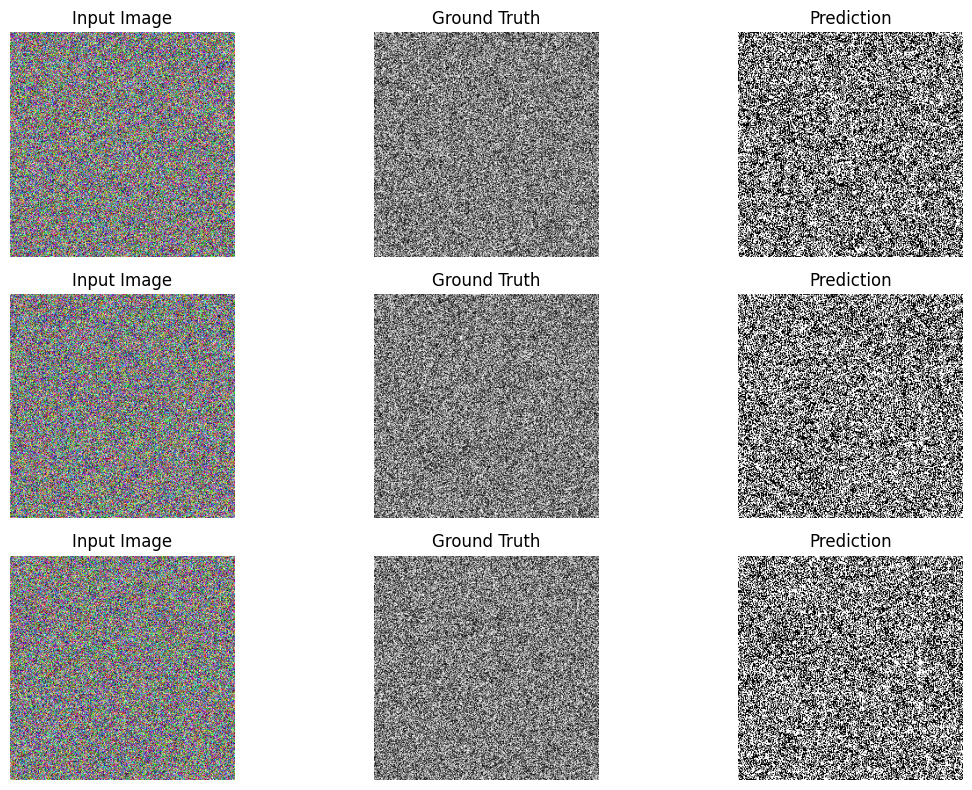

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

print("Creating synthetic data...")
train_images = [np.random.rand(3, 256, 256).astype(np.float32) for _ in range(20)]
train_masks = [np.random.rand(1, 256, 256).astype(np.float32) for _ in range(20)]

test_images = [np.random.rand(3, 256, 256).astype(np.float32) for _ in range(5)]
test_masks = [np.random.rand(1, 256, 256).astype(np.float32) for _ in range(5)]

print(f"Training samples: {len(train_images)}")
print(f"Test samples: {len(test_images)}")

class SegmentationDataset(Dataset):
    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = torch.from_numpy(self.images[idx]).float()
        mask = torch.from_numpy(self.masks[idx]).float()

        if image.dim() == 3 and image.shape[-1] == 3:
            image = image.permute(2, 0, 1)
        if mask.dim() == 2:
            mask = mask.unsqueeze(0)

        return image, mask

def custom_collate_fn(batch):
    images, masks = zip(*batch)
    max_h = max(img.shape[1] for img in images)
    max_w = max(img.shape[2] for img in images)

    resized_images = []
    resized_masks = []

    for img, mask in zip(images, masks):
        pad_h = max_h - img.shape[1]
        pad_w = max_w - img.shape[2]
        img = F.pad(img, (0, pad_w, 0, pad_h))
        mask = F.pad(mask, (0, pad_w, 0, pad_h))
        resized_images.append(img)
        resized_masks.append(mask)

    return torch.stack(resized_images), torch.stack(resized_masks)

train_dataset = SegmentationDataset(train_images, train_masks)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, collate_fn=custom_collate_fn)

test_dataset = SegmentationDataset(test_images, test_masks)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, collate_fn=custom_collate_fn)

class UNET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNET, self).__init__()
        self.enc1 = self.conv_block(in_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = self.conv_block(512, 1024)
        self.upconv4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = self.conv_block(1024, 512)
        self.upconv3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = self.conv_block(512, 256)
        self.upconv2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = self.conv_block(256, 128)
        self.upconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = self.conv_block(128, 64)
        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def conv_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat((self.upconv4(b), e4), dim=1))
        d3 = self.dec3(torch.cat((self.upconv3(d4), e3), dim=1))
        d2 = self.dec2(torch.cat((self.upconv2(d3), e2), dim=1))
        d1 = self.dec1(torch.cat((self.upconv1(d2), e1), dim=1))
        return torch.sigmoid(self.final(d1))

class FAPNET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(FAPNET, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.level3 = nn.Conv2d(64, 128, 3, padding=1)
        self.level4 = nn.Conv2d(128, 256, 3, padding=1)
        self.up1 = nn.Conv2d(256, 128, 3, padding=1)
        self.up2 = nn.Conv2d(128, 64, 3, padding=1)
        self.up3 = nn.Conv2d(64, 32, 3, padding=1)
        self.final = nn.Conv2d(32, out_channels, 1)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        x = self.relu(self.level3(x))
        x = self.pool(x)
        x = self.relu(self.level4(x))
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.relu(self.up1(x))
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.relu(self.up2(x))
        x = self.relu(self.up3(x))
        return torch.sigmoid(self.final(x))

class PLANET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(PLANET, self).__init__()
        self.e1 = self.block(in_channels, 32)
        self.e2 = self.block(32, 64)
        self.e3 = self.block(64, 128)
        self.e4 = self.block(128, 256)
        self.e5 = self.block(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.d4 = self.block(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.d3 = self.block(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.d2 = self.block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.d1 = self.block(64, 32)
        self.final = nn.Conv2d(32, out_channels, 1)

    def block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2))
        e4 = self.e4(self.pool(e3))
        e5 = self.e5(self.pool(e4))
        x = self.up4(e5)
        x = self.d4(torch.cat((x, e4), dim=1))
        x = self.up3(x)
        x = self.d3(torch.cat((x, e3), dim=1))
        x = self.up2(x)
        x = self.d2(torch.cat((x, e2), dim=1))
        x = self.up1(x)
        x = self.d1(torch.cat((x, e1), dim=1))
        return torch.sigmoid(self.final(x))

def train_model(model, train_loader, epochs=15, device='cpu'):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    criterion = nn.BCELoss()

    print(f"Starting training {model.__class__.__name__} on {device}...")

    for epoch in range(epochs):
        model.train()
        train_loss = 0

        for batch_idx, (data, target) in enumerate(train_loader):
            data = data.to(device).float()
            target = target.to(device).float()

            optimizer.zero_grad()
            output = model(data)

            if output.shape != target.shape:
                output = F.interpolate(output, size=target.shape[2:], mode='bilinear', align_corners=False)

            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} completed. Avg Loss: {train_loss/len(train_loader):.4f}")

    print(f"Training {model.__class__.__name__} finished.\n")
    return model

def evaluate_model(model, test_loader, device='cpu'):
    model.eval()
    criterion = nn.BCELoss()
    total_loss = 0
    correct = 0
    total = 0

    print(f"Evaluating {model.__class__.__name__}...")
    with torch.no_grad():
        for data, target in test_loader:
            data = data.to(device).float()
            target = target.to(device).float()

            output = model(data)

            if output.shape != target.shape:
                output = F.interpolate(output, size=target.shape[2:], mode='bilinear', align_corners=False)

            loss = criterion(output, target)
            total_loss += loss.item()

            predicted = (output > 0.5).float()
            correct += (predicted == target).sum().item()
            total += target.numel()

    avg_loss = total_loss / len(test_loader)
    accuracy = correct / total
    print(f"Test Loss: {avg_loss:.4f} | Test Accuracy: {accuracy * 100:.2f}%\n")

def visualize_predictions(model, data_loader, device='cpu'):
    model.eval()
    data, target = next(iter(data_loader))
    data = data.to(device).float()

    with torch.no_grad():
        output = model(data)
        output = (output > 0.5).float()

    data = data.cpu()
    target = target.cpu()
    output = output.cpu()

    plt.figure(figsize=(12, 8))
    for i in range(min(3, len(data))):
        plt.subplot(3, 3, i*3 + 1)
        plt.imshow(data[i].permute(1, 2, 0).squeeze())
        plt.title("Input Image")
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 2)
        plt.imshow(target[i].squeeze(), cmap='gray')
        plt.title("Ground Truth")
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 3)
        plt.imshow(output[i].squeeze(), cmap='gray')
        plt.title("Prediction")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

print("="*50)
print("TRAINING MODELS")
print("="*50)

unet_model = train_model(UNET(), train_loader, epochs=15, device=device)
fapnet_model = train_model(FAPNET(), train_loader, epochs=15, device=device)
planet_model = train_model(PLANET(), train_loader, epochs=15, device=device)

print("="*50)
print("TESTING RESULTS")
print("="*50)

evaluate_model(unet_model, test_loader, device=device)
evaluate_model(fapnet_model, test_loader, device=device)
evaluate_model(planet_model, test_loader, device=device)

print("="*50)
print("VISUALIZING PREDICTIONS (UNET)")
print("="*50)
visualize_predictions(unet_model, test_loader, device=device)

In [ ]:
!pip install geopandas rasterio shapely

Number of features: 1
CRS: EPSG:4326
State: ['Chhattisgarh']

✅ Chhattisgarh shapefile created!
📁 /content/Chhattisgarh.shp
📦 /content/Chhattisgarh.zip


<Axes: >

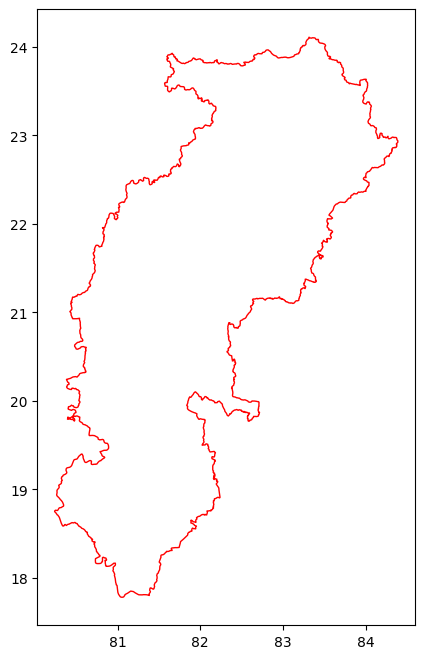

In [ ]:
# ============================================================
# CHHATTISGARH SHAPEFILE
# ============================================================

!wget -q https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IND_1.json \
    -O /content/gadm41_IND_1.json

import geopandas as gpd
import os
import zipfile

# Read India state boundaries
india = gpd.read_file("/content/gadm41_IND_1.json")

# Select Chhattisgarh
cg = india[india["NAME_1"].str.lower() == "chhattisgarh"].copy()

print("Number of features:", len(cg))
print("CRS:", cg.crs)
print("State:", cg["NAME_1"].tolist())

# Save shapefile
output = "/content/Chhattisgarh.shp"
cg.to_file(output, driver="ESRI Shapefile")

# Zip all shapefile components
files = [
    "/content/Chhattisgarh.shp",
    "/content/Chhattisgarh.shx",
    "/content/Chhattisgarh.dbf",
    "/content/Chhattisgarh.prj",
    "/content/Chhattisgarh.cpg"
]

with zipfile.ZipFile("/content/Chhattisgarh.zip", "w") as z:
    for f in files:
        if os.path.exists(f):
            z.write(f, os.path.basename(f))

print("\n✅ Chhattisgarh shapefile created!")
print("📁 /content/Chhattisgarh.shp")
print("📦 /content/Chhattisgarh.zip")

cg.plot(figsize=(8, 8), edgecolor="red", facecolor="none")

In [ ]:
from google.colab import files

files.download("/content/Chhattisgarh.zip")

Map = geemap.Map(center=[21.3, 82.0], zoom=7)
Map.add_basemap("SATELLITE")

Map.addLayer(
    chhattisgarh,
    {"color": "red"},
    "Chhattisgarh Boundary"
)

Map

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Map(center=[21.3, 82.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

In [ ]:
print("S2 beginning:", s2_b.bandNames().getInfo())
print("S2 middle:", s2_m.bandNames().getInfo())
print("S2 end:", s2_e.bandNames().getInfo())

print("S1 beginning:", s1_b.bandNames().getInfo())
print("S1 middle:", s1_m.bandNames().getInfo())
print("S1 end:", s1_e.bandNames().getInfo())

print("All composites are ready")

actual_image = ee.Image.cat([
    s2_b.select('B8'),
    s2_m.select('B8'),
    s2_e.select('B8')
]).clip(chhattisgarh_region)

print("Actual 3-channel image created")

actual_image = actual_image.clip(chhattisgarh_region)

print("Image clipped to actual Chhattisgarh boundary")
print("Bands:", actual_image.bandNames().getInfo())

S2 beginning: ['B4', 'B8', 'B11']
S2 middle: ['B4', 'B8', 'B11']
S2 end: ['B4', 'B8', 'B11']
S1 beginning: ['VH', 'VV']
S1 middle: ['VH', 'VV']
S1 end: ['VH', 'VV']
All composites are ready
Actual 3-channel image created
Image clipped to actual Chhattisgarh boundary
Bands: ['B8', 'B8_1', 'B8_2']


In [ ]:
import geemap

Map = geemap.Map(center=[21.25, 82.0], zoom=7)
Map.add_basemap("SATELLITE")

Map.addLayer(
    actual_image,
    {
        'min': 500,
        'max': 4000,
        'bands': ['B8', 'B8_1', 'B8_2']
    },
    '3-period NIR composite'
)

Map.addLayer(
    chhattisgarh.style(
        color='red',
        fillColor='00000000',
        width=3
    ),
    {},
    'Chhattisgarh Boundary'
)

Map

NameError: name 'geemap' is not defined